In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

In [2]:
PROJECT_ROOT = r"D:\AI-Powered-Diabetic-Retinopathy-System"

CSV_PATH = os.path.join(
    PROJECT_ROOT,
    "ml-model",
    "dataset",
    "raw",
    "train.csv"
)

IMAGE_DIR = os.path.join(
    PROJECT_ROOT,
    "ml-model",
    "dataset",
    "raw",
    "train_images"
)

MODEL_DIR = os.path.join(
    PROJECT_ROOT,
    "ml-model",
    "saved_models"
)

IMAGE_SIZE = (224, 224)

CLASS_NAMES = [
    "No DR",
    "Mild DR",
    "Moderate DR",
    "Severe DR",
    "Proliferative DR"
]

NUM_CLASSES = 5

In [3]:
df = pd.read_csv(CSV_PATH)

# Create image paths
df["image_path"] = df["id_code"].apply(
    lambda x: os.path.join(IMAGE_DIR, x + ".png")
)

# Keep only valid image paths
df = df[df["image_path"].apply(os.path.exists)].copy()

print("Total valid images:", len(df))

Total valid images: 3662


In [4]:
# ------------------------------------------------------------
# STEP 1: Separate TEST = 15%
# ------------------------------------------------------------

train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["diagnosis"],
    random_state=42
)

# ------------------------------------------------------------
# STEP 2: Separate VALIDATION = 15% of total
# ------------------------------------------------------------

validation_fraction = 0.15 / 0.85

train_df, val_df = train_test_split(
    train_val_df,
    test_size=validation_fraction,
    stratify=train_val_df["diagnosis"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 2562
Validation: 550
Test: 550


In [5]:
def load_test_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_png(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label


test_paths = test_df["image_path"].values
test_labels = test_df["diagnosis"].values.astype(np.int32)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_dataset = test_dataset.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(8)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

In [7]:
efficientnet_path = os.path.join(
    MODEL_DIR,
    "best_efficientnet.keras"
)

resnet_path = os.path.join(
    MODEL_DIR,
    "best_resnet50.keras"
)

resnet_finetuned_path = os.path.join(
    MODEL_DIR,
    "resnet50_finetuned.keras"
)

efficientnet_model = tf.keras.models.load_model(
    efficientnet_path
)

resnet_model = tf.keras.models.load_model(
    resnet_path
)

resnet_finetuned_model = tf.keras.models.load_model(
    resnet_finetuned_path
)

print("All models loaded successfully.")

All models loaded successfully.


In [8]:
y_true = test_labels

efficientnet_probs = efficientnet_model.predict(
    test_dataset,
    verbose=1
)

resnet_probs = resnet_model.predict(
    test_dataset,
    verbose=1
)

resnet_finetuned_probs = resnet_finetuned_model.predict(
    test_dataset,
    verbose=1
)

print("Prediction shapes:")
print("EfficientNet-B0:", efficientnet_probs.shape)
print("ResNet50:", resnet_probs.shape)
print("ResNet50 Fine-tuned:", resnet_finetuned_probs.shape)

69/69 ━━━━━━━━━━━━━━━━━━━━ 18s 218ms/step
69/69 ━━━━━━━━━━━━━━━━━━━━ 32s 436ms/step
69/69 ━━━━━━━━━━━━━━━━━━━━ 34s 456ms/step
Prediction shapes:
EfficientNet-B0: (550, 5)
ResNet50: (550, 5)
ResNet50 Fine-tuned: (550, 5)


In [9]:
def plot_multiclass_roc(
    ax,
    y_true,
    probabilities,
    title
):

    # Convert labels to one-vs-rest format
    y_true_binary = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    # --------------------------------------------------------
    # Plot ROC curve for each class
    # --------------------------------------------------------

    for class_id in range(NUM_CLASSES):

        fpr, tpr, _ = roc_curve(
            y_true_binary[:, class_id],
            probabilities[:, class_id]
        )

        roc_auc = auc(
            fpr,
            tpr
        )

        ax.plot(
            fpr,
            tpr,
            linewidth=1.5,
            label=f"{CLASS_NAMES[class_id]} (AUC = {roc_auc:.3f})"
        )

    # --------------------------------------------------------
    # Macro-average ROC
    # --------------------------------------------------------

    all_fpr = np.unique(
        np.concatenate([
            roc_curve(
                y_true_binary[:, i],
                probabilities[:, i]
            )[0]
            for i in range(NUM_CLASSES)
        ])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(NUM_CLASSES):

        fpr, tpr, _ = roc_curve(
            y_true_binary[:, i],
            probabilities[:, i]
        )

        mean_tpr += np.interp(
            all_fpr,
            fpr,
            tpr
        )

    mean_tpr /= NUM_CLASSES

    macro_auc = auc(
        all_fpr,
        mean_tpr
    )

    ax.plot(
        all_fpr,
        mean_tpr,
        linestyle="--",
        linewidth=1.8,
        label=f"Macro-average (AUC = {macro_auc:.3f})"
    )

    # --------------------------------------------------------
    # Random classifier
    # --------------------------------------------------------

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1
    )

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=10,
        fontweight="bold"
    )

    ax.set_xlabel(
        "False Positive Rate",
        fontsize=8
    )

    ax.set_ylabel(
        "True Positive Rate",
        fontsize=8
    )

    ax.set_xlim(
        0,
        1
    )

    ax.set_ylim(
        0,
        1.05
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        fontsize=6,
        loc="lower right"
    )

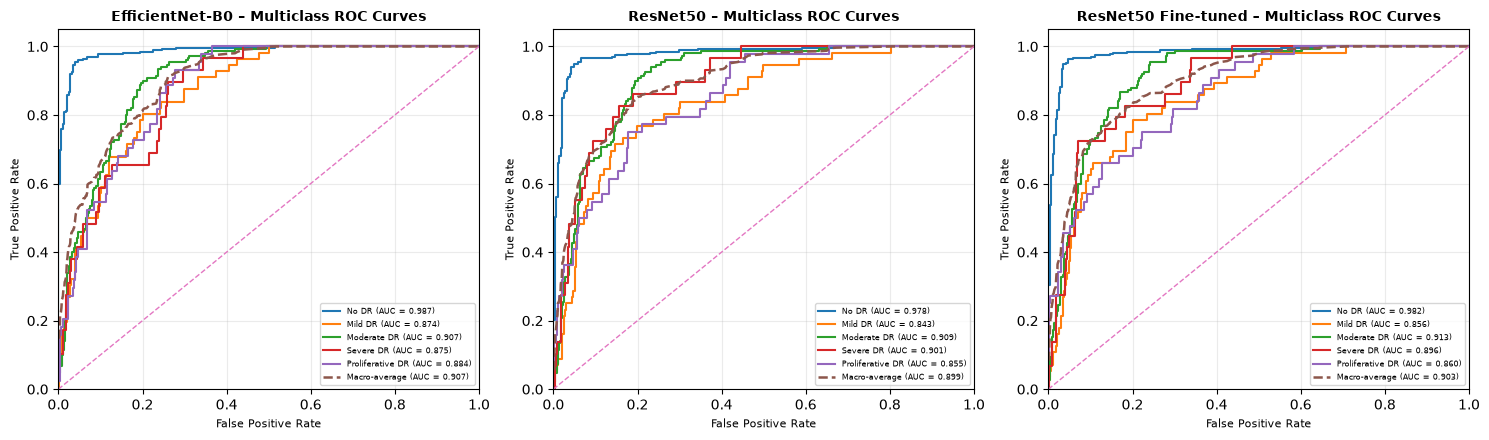

In [10]:

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5)
)

plot_multiclass_roc(
    axes[0],
    y_true,
    efficientnet_probs,
    "EfficientNet-B0 – Multiclass ROC Curves"
)

plot_multiclass_roc(
    axes[1],
    y_true,
    resnet_probs,
    "ResNet50 – Multiclass ROC Curves"
)

plot_multiclass_roc(
    axes[2],
    y_true,
    resnet_finetuned_probs,
    "ResNet50 Fine-tuned – Multiclass ROC Curves"
)

plt.tight_layout()

plt.savefig(
    "roc_curves_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
def print_roc_auc(
    model_name,
    y_true,
    probabilities
):

    y_true_binary = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    for class_id in range(NUM_CLASSES):

        auc_value = roc_auc_score(
            y_true_binary[:, class_id],
            probabilities[:, class_id]
        )

        print(
            f"{CLASS_NAMES[class_id]:20s}: "
            f"{auc_value:.4f}"
        )

    macro_auc = roc_auc_score(
        y_true_binary,
        probabilities,
        average="macro",
        multi_class="ovr"
    )

    print("-" * 60)

    print(
        f"{'Macro ROC-AUC':20s}: "
        f"{macro_auc:.4f}"
    )

In [12]:
print_roc_auc(
    "EfficientNet-B0",
    y_true,
    efficientnet_probs
)

print_roc_auc(
    "ResNet50",
    y_true,
    resnet_probs
)

print_roc_auc(
    "ResNet50 Fine-tuned",
    y_true,
    resnet_finetuned_probs
)


EfficientNet-B0
No DR               : 0.9869
Mild DR             : 0.8744
Moderate DR         : 0.9074
Severe DR           : 0.8746
Proliferative DR    : 0.8843
------------------------------------------------------------
Macro ROC-AUC       : 0.9055

ResNet50
No DR               : 0.9785
Mild DR             : 0.8429
Moderate DR         : 0.9092
Severe DR           : 0.9007
Proliferative DR    : 0.8551
------------------------------------------------------------
Macro ROC-AUC       : 0.8973

ResNet50 Fine-tuned
No DR               : 0.9816
Mild DR             : 0.8565
Moderate DR         : 0.9134
Severe DR           : 0.8958
Proliferative DR    : 0.8600
------------------------------------------------------------
Macro ROC-AUC       : 0.9015
